In [3]:
# 匯入TensorFlow中的Keras套件，用來建立及訓練神經網路模型
from tensorflow import keras

# 匯入Sequential模型，可以依序堆疊神經網路的各個層
from keras.models import Sequential

# 匯入Dense（全連接層）、Flatten（資料攤平層）、Dropout（隨機停用神經元層）
from keras.layers import Dense, Flatten,Dropout

In [4]:
# 載入MNIST資料集，並將資料分成訓練資料及測試資料
mnist=keras.datasets.mnist

# (1.)train_data：訓練圖片
# (2.)train_label：訓練圖片對應的正確數字
# (3.)test_data：測試圖片
# (4.)test_label：測試圖片對應的正確數字
(train_data, train_label), (test_data, test_label) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [5]:
# 查看變數所儲存的資料型態
print(type(train_data))

# 查看訓練圖片資料的形狀
# 結果為(60000, 28, 28)，代表60000張圖片，每張圖片為28×28像素
print(train_data.shape)

# 查看訓練標籤的資料型態
print(type(train_label))

# 查看訓練標籤的形狀
# 結果為(60000,)，代表有60000個標籤，每個標籤代表一張圖片的正確數字
print(train_label.shape)

# 查看測試圖片資料的形狀
# 結果為(10000, 28, 28)，代表10000張測試圖片，每張圖片為28×28像素
print(test_data.shape)

# 查看測試標籤的形狀
# 結果為(10000,)，代表有10000個測試標籤
print(test_label.shape)

<class 'numpy.ndarray'>
(60000, 28, 28)
<class 'numpy.ndarray'>
(60000,)
(10000, 28, 28)
(10000,)


In [10]:
# 印出第1張訓練圖片所對應的正確數字
# 索引從0開始，train_label[0]代表第1筆資料的標籤
print(train_label[0])

print("--------------------------------------")

# 印出第1張訓練圖片的像素資料
# 每張圖片有28×28個像素，每個像素以數值表示灰階深淺
print(train_data[0])

5
--------------------------------------
[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136
  175  26 166 255 247 127   0   0   0   0]
 [  0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253
  225 172 253 242 195  64   0   0   0   0]
 [  0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251
   93  82  82  56  39   0   0   0   0   0]
 [  0   0   0   0   0  

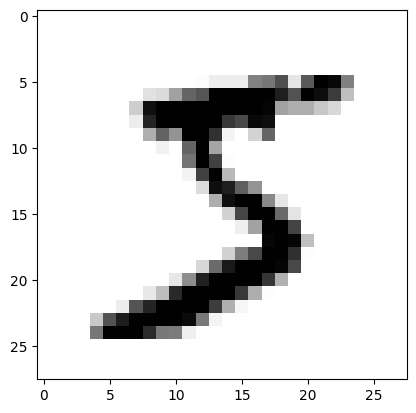

In [ ]:
# 匯入Matplotlib的pyplot模組，用來繪製及顯示圖片
import matplotlib.pyplot as plt

# 顯示第1張訓練圖片
# cmap='binary'代表使用黑白色階顯示圖片
plt.imshow(train_data[0], cmap='binary')

# 將圖片顯示出來
plt.show()

In [ ]:
# 建立Sequential模型，讓神經網路的各層依照加入順序進行運算
model=Sequential()

# 加入Flatten層，將原本28×28的二維圖片攤平成784個數值的一維資料
model.add(Flatten())

# 加入Dense全連接層，設定512個神經元(準確率較高)，使用ReLU啟動函數
# input_dim=784代表每筆輸入資料有784(為28×28)個特徵
model.add(Dense(512, activation='relu', input_dim=784))

# 加入Dropout層，設定比例為0.2。在訓練過程中隨機停用20%的神經元，降低模型過度擬合的風險
model.add(Dropout(0.2))

# 加入輸出層，設定10個神經元，分別對應數字0～9
# softmax會將輸出轉換成總和為1的機率分布，方便判斷各數字的可能性
model.add(Dense(10, activation='softmax'))

# 設定模型的訓練方式
# (1.)optimizer='rmsprop'：使用RMSprop優化器調整神經網路的權重
# (2.)loss='sparse_categorical_crossentropy'：用於多分類問題，且標籤是整數形式
# (3.)metrics=['accuracy']：訓練及評估時顯示準確率
model.compile(optimizer='rmsprop', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [ ]:
# 開始訓練模型
# (1.)train_data：提供訓練圖片
# (2.)train_label：提供每張圖片對應的正確答案
# (3.)epochs=20：將全部訓練資料完整訓練20次
# (4.)batch_size=512：每次取512筆資料進行一次權重更新
model.fit(train_data,train_label,epochs=20,batch_size=512)

# 使用測試資料評估模型的表現，evaluate會回傳損失值（loss）及準確率（accuracy）
score=model.evaluate(test_data, test_label)

# 印出測試資料的準確率，score[0]代表損失值，score[1]代表準確率
print(score[1])

Epoch 1/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.8478 - loss: 11.5705
Epoch 2/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9271 - loss: 0.8685
Epoch 3/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9441 - loss: 0.4516
Epoch 4/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9554 - loss: 0.3265
Epoch 5/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9627 - loss: 0.2628
Epoch 6/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9675 - loss: 0.2354
Epoch 7/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9722 - loss: 0.1964
Epoch 8/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9728 - loss: 0.1818
Epoch 9/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9759 - loss: 0.1775
Epoch 10/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9783 - loss: 0.1544
Epoch 11/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9795 - loss: 0.1586
Epoch 12/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/st